In [1]:
import os
# [QAT UPDATE]: Set legacy Keras to avoid TFMOT compatibility issues with Keras 3 on Kaggle
os.environ["TF_USE_LEGACY_KERAS"] = "1"

# [QAT UPDATE]: Added tensorflow-model-optimization to pip install
os.system('pip install -q huggingface_hub tensorflow-model-optimization "numpy<2.0.0"')

0

In [2]:
import json
import shutil
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

2026-04-12 14:00:49.393222: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1776002449.571997     113 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1776002449.625647     113 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1776002450.056693     113 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776002450.056746     113 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1776002450.056749     113 computation_placer.cc:177] computation placer alr

In [3]:
# [QAT UPDATE]: Import TensorFlow Model Optimization
import tensorflow_model_optimization as tfmot

# [UPDATED IMPORTS] Must use tensorflow.keras strictly for TFMOT compatibility
from tensorflow.keras.layers import (Input, TimeDistributed, GlobalAveragePooling2D,
                                     Bidirectional, LSTM, Dense, Dropout)
from tensorflow.keras.models import Sequential, load_model, Model
from tensorflow.keras.utils import to_categorical, Sequence
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
 
from sklearn.model_selection import train_test_split
 
from huggingface_hub import HfApi, hf_hub_download
from huggingface_hub.utils import EntryNotFoundError, RepositoryNotFoundError
from kaggle_secrets import UserSecretsClient

In [4]:
plt.style.use("seaborn-v0_8")
IMAGE_HEIGHT    = 224
IMAGE_WIDTH     = 224
SEQUENCE_LENGTH = 16
BATCH_SIZE      = 8
EPOCHS          = 10
CLASSES_LIST    =["NonViolence", "Violence"]
DATASET_PATH    = "/kaggle/input/datasets/mohamedmustafa/real-life-violence-situations-dataset/Real Life Violence Dataset"
RESUME        = True
HF_TOKEN      = UserSecretsClient().get_secret("HF_TOKEN")
api           = HfApi(token=HF_TOKEN)
HF_REPO_ID    = f"{api.whoami()['name']}/MoBiLSTM-AwareTraining-violence-detection"
api.create_repo(repo_id=HF_REPO_ID, repo_type="model", private=True, exist_ok=True)
print(f"[HF] Repo → https://huggingface.co/{HF_REPO_ID}")

[HF] Repo → https://huggingface.co/basant18/MoBiLSTM-AwareTraining-violence-detection


In [5]:
HF_MODEL_FILE = "model_qat.keras"
HF_META_FILE  = "training_state_qat.json"
LOCAL_DIR     = "/kaggle/working/hf_checkpoint"
LOCAL_CKPT    = os.path.join(LOCAL_DIR, HF_MODEL_FILE)
LOCAL_META    = os.path.join(LOCAL_DIR, HF_META_FILE)
os.makedirs(LOCAL_DIR, exist_ok=True)

In [6]:
print("=" * 50)
print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ {len(gpus)} GPU(s) detected:")
        for g in gpus:
            print("  •", g.name)
    except RuntimeError as e:
        print("GPU config error:", e)
else:
    print("⚠️  No GPU detected – running on CPU.")
print("=" * 50)
# [QAT UPDATE]: Removed mixed_precision. QAT simulates INT8 using float32 operations. 
# Mixed float16 interferes with fake-quantization nodes.
print("Quantization-Aware Training (QAT) Enabled - Mixed precision disabled to prevent conflicts.")

TensorFlow version: 2.19.0
✅ 1 GPU(s) detected:
  • /physical_device:GPU:0
Quantization-Aware Training (QAT) Enabled - Mixed precision disabled to prevent conflicts.


In [7]:
def upload_to_hf(api: HfApi, local_path: str, repo_filename: str):
    api.upload_file(
        path_or_fileobj=local_path,
        path_in_repo=repo_filename,
        repo_id=HF_REPO_ID,
        repo_type="model",
    )
    print(f"  ☁️  Uploaded  {repo_filename}  →  {HF_REPO_ID}")

In [8]:
def download_from_hf(repo_filename: str, local_path: str) -> bool:
    try:
        downloaded = hf_hub_download(
            repo_id=HF_REPO_ID,
            filename=repo_filename,
            token=HF_TOKEN,
            local_dir=LOCAL_DIR,
        )
        if downloaded != local_path:
            shutil.copy(downloaded, local_path)
        print(f"  ⬇️  Downloaded  {repo_filename}  from  {HF_REPO_ID}")
        return True
    except (EntryNotFoundError, RepositoryNotFoundError):
        return False
    except Exception as e:
        print(f"  ⚠️  Could not download {repo_filename}: {e}")
        return False

In [9]:
def load_training_state() -> dict:
    if not RESUME:
        print("  📋 RESUME=False – starting from scratch.")
        return {"epoch": 0, "metrics": {}}
 
    found = download_from_hf(HF_META_FILE, LOCAL_META)
    if found and os.path.exists(LOCAL_META):
        with open(LOCAL_META) as f:
            state = json.load(f)
        epoch   = state.get("epoch", 0)
        val_acc = state.get("metrics", {}).get("val_accuracy", 0.0)
        print(f"  📋 Resuming from epoch {epoch}  "
              f"(best val_acc so far: {val_acc:.4f})")
        return state
 
    print("  📋 No previous state found – starting from scratch.")
    return {"epoch": 0, "metrics": {}}

In [10]:
def save_training_state(state: dict):
    with open(LOCAL_META, "w") as f:
        json.dump(state, f, indent=2)

In [11]:
class HuggingFaceCheckpoint(Callback):
    def __init__(self, api: HfApi, state: dict):
        super().__init__()
        self.api   = api
        self.state = state
 
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        current_epoch = self.state["epoch"] + epoch + 1
 
        print(f"\n  💾 Epoch {current_epoch} ended — saving checkpoint …")
        self.model.save(LOCAL_CKPT)
 
        lr = float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        metrics = {
            "accuracy":      float(logs.get("accuracy",     0.0)),
            "loss":          float(logs.get("loss",         0.0)),
            "val_accuracy":  float(logs.get("val_accuracy", 0.0)),
            "val_loss":      float(logs.get("val_loss",     0.0)),
            "learning_rate": lr,
        }
 
        self.state["epoch"]   = current_epoch
        self.state["metrics"] = metrics
 
        try:
            upload_to_hf(self.api, LOCAL_CKPT, HF_MODEL_FILE)
            save_training_state(self.state)
            upload_to_hf(self.api, LOCAL_META, HF_META_FILE)
            print(f"  ✅ Epoch {current_epoch} checkpoint pushed to HuggingFace.")
        except Exception as e:
            print(f"  ⚠️  HF upload failed (training continues locally): {e}")

In [12]:
def frames_extraction(video_path: str) -> list:
    frames_list =[]
    try:
        cap = cv2.VideoCapture(video_path)
        frames =[]
        gray_frames =[]

        while True:
            ret, frame = cap.read()
            if not ret:
                break
            
            frame = cv2.resize(frame, (IMAGE_WIDTH, IMAGE_HEIGHT))
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)
            
            gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
            gray_frames.append(gray)

        cap.release()

        num_frames = len(frames)
        if num_frames == 0:
            return[]

        if num_frames < SEQUENCE_LENGTH:
            while len(frames) < SEQUENCE_LENGTH:
                frames.append(frames[-1])
                gray_frames.append(gray_frames[-1])
            num_frames = SEQUENCE_LENGTH

        motion_scores =[]
        for i in range(num_frames - 1):
            diff = cv2.absdiff(gray_frames[i], gray_frames[i+1])
            motion_scores.append(np.sum(diff))

        max_motion = -1
        best_start_idx = 0
        window_size = SEQUENCE_LENGTH - 1

        for i in range(num_frames - SEQUENCE_LENGTH + 1):
            window_motion = sum(motion_scores[i : i + window_size])
            if window_motion > max_motion:
                max_motion = window_motion
                best_start_idx = i

        best_frames = frames[best_start_idx : best_start_idx + SEQUENCE_LENGTH]

        for frame in best_frames:
            frame = preprocess_input(frame.astype(np.float32))
            frames_list.append(frame)

    except Exception as e:
        print(f"[frames_extraction] Error reading {video_path}: {e}")

    return frames_list

In [13]:
def collect_video_paths(dataset_path: str, classes: list):
    video_paths, labels = [],[]
    for class_index, class_name in enumerate(classes):
        class_dir = os.path.join(dataset_path, class_name)
        if not os.path.isdir(class_dir):
            print(f"  ⚠️  Directory not found: {class_dir}")
            continue
        files = os.listdir(class_dir)
        for file_name in files:
            if file_name.endswith(('.mp4', '.avi', '.mov')):
                video_paths.append(os.path.join(class_dir, file_name))
                labels.append(class_index)
        print(f"  Found {len(files)} videos for class '{class_name}'")
    return np.array(video_paths), np.array(labels)

In [14]:
class VideoDataGenerator(Sequence):
    def __init__(self, video_paths, labels, batch_size=BATCH_SIZE, shuffle=True):
        super().__init__()
        self.video_paths = video_paths
        self.labels      = labels
        self.batch_size  = batch_size
        self.shuffle     = shuffle
        self.indices     = np.arange(len(video_paths))
        self.on_epoch_end()
 
    def __len__(self):
        return max(1, len(self.video_paths) // self.batch_size)
 
    def __getitem__(self, idx):
        batch_idx = self.indices[
            idx * self.batch_size : (idx + 1) * self.batch_size
        ]
        X, y = [],[]
        for i in batch_idx:
            frames = frames_extraction(self.video_paths[i])
            if len(frames) == SEQUENCE_LENGTH:
                X.append(frames)
                y.append(self.labels[i])
 
        if len(X) == 0:
            X = np.zeros((self.batch_size, SEQUENCE_LENGTH,
                          IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.float32)
            y = to_categorical([0] * self.batch_size, num_classes=len(CLASSES_LIST))
            return X, y
 
        while len(X) < self.batch_size:
            X.append(X[0])
            y.append(y[0])
 
        return (np.array(X, dtype=np.float32),
                to_categorical(y, num_classes=len(CLASSES_LIST)))
 
    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

In [15]:
# Keep the global helper functions defined exactly as before
@tf.keras.utils.register_keras_serializable(package='Custom')
def flatten_time(x):
    return tf.reshape(x, [-1, IMAGE_HEIGHT, IMAGE_WIDTH, 3])

@tf.keras.utils.register_keras_serializable(package='Custom')
def unflatten_time(x):
    return tf.reshape(x, [-1, SEQUENCE_LENGTH, 1280])

In [16]:
def create_model() -> Model:
    # ==========================================
    # PART 1: Quantize the MobileNetV2 Base
    # ==========================================
    mobilenet = MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(IMAGE_HEIGHT, IMAGE_WIDTH, 3),
    )
    mobilenet.trainable = True
    for layer in mobilenet.layers[:-40]:
        layer.trainable = False
        
    # Quantize flat sub-model independently (CNN layers are fully supported)
    qat_mobilenet = tfmot.quantization.keras.quantize_model(mobilenet)
    
    # ==========================================
    # PART 2: Quantize the LSTM Classifier Head
    # ==========================================
    class_input = Input(shape=(SEQUENCE_LENGTH, 1280), name="class_input")
    x = Dropout(0.3)(class_input)
    
    # ⚠️ Leave the Bidirectional/LSTM layers un-annotated so they remain in float32
    x = Bidirectional(
        LSTM(units=64, return_sequences=False),
        backward_layer=LSTM(units=64, go_backwards=True, return_sequences=False),
        name="bidi_lstm"
    )(x)
    x = Dropout(0.3)(x)
    
    # ✅ Explicitly annotate the Dense layers to be quantized
    x = tfmot.quantization.keras.quantize_annotate_layer(
        Dense(128, activation="relu", name="dense_128")
    )(x)
    x = Dropout(0.3)(x)
    
    class_output = tfmot.quantization.keras.quantize_annotate_layer(
        Dense(len(CLASSES_LIST), activation="softmax", dtype="float32", name="output")
    )(x)
    
    classifier_model = Model(inputs=class_input, outputs=class_output, name="classifier_model")
    
    # Quantize ONLY the annotated layers (Dense layers)
    qat_classifier = tfmot.quantization.keras.quantize_apply(classifier_model)
    
    # ==========================================
    # PART 3: Stitch Them Together
    # ==========================================
    inputs = Input(shape=(SEQUENCE_LENGTH, IMAGE_HEIGHT, IMAGE_WIDTH, 3), name="video_input")
    
    # Flow data: Input -> Reshape -> QAT MobileNet -> Pool -> Reshape -> QAT Classifier
    y = tf.keras.layers.Lambda(flatten_time, name="flatten_time")(inputs)
    y = qat_mobilenet(y)
    y = GlobalAveragePooling2D()(y)
    y = tf.keras.layers.Lambda(unflatten_time, name="unflatten_time")(y)
    outputs = qat_classifier(y)
    
    # Combine into the final, fully-quantized model!
    final_model = Model(inputs=inputs, outputs=outputs, name="qat_video_model")
    
    return final_model

In [17]:
def plot_training(history: dict):
    if not history:
        print("No history data to plot yet.")
        return
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.get("accuracy",     []), label="Train Acc")
    axes[0].plot(history.get("val_accuracy", []), label="Val Acc")
    axes[0].set_title("Accuracy (all epochs)")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history.get("loss",[]), label="Train Loss")
    axes[1].plot(history.get("val_loss", []), label="Val Loss")
    axes[1].set_title("Loss (all epochs)")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=150)
    plt.show()
    print("📊 Training curves saved → training_curves.png")



🤗 HuggingFace ready → basant18/MoBiLSTM-AwareTraining-violence-detection
  📋 No previous state found – starting from scratch.

▶️  Epoch 1 → 10  (10 epoch(s) remaining)

📂 Scanning dataset …
  Found 1000 videos for class 'NonViolence'
  Found 1000 videos for class 'Violence'
   Total videos: 2000
   Train: 1600  |  Val: 400
Train batches: 200  |  Val batches: 50
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)

🖥️  Devices in strategy: 1
  🆕 No checkpoint found – building fresh QAT model …
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).


I0000 00:00:1776002517.606663     113 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

I0000 00:00:1776002554.776340     176 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1776002558.401170     179 service.cc:152] XLA service 0x7d4d2c6532f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1776002558.401223     179 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1776002558.714082     179 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


177/200 [=========================>....] - ETA: 33s - loss: 0.5070 - accuracy: 0.7394

...

New Data Upload: |          |  0.00B /  0.00B            

  ☁️  Uploaded  model_qat.keras  →  basant18/MoBiLSTM-AwareTraining-violence-detection
  ☁️  Uploaded  training_state_qat.json  →  basant18/MoBiLSTM-AwareTraining-violence-detection
  ✅ Epoch 55 checkpoint pushed to HuggingFace.
200/200 [==============================] - 346s 2s/step - loss: 0.0439 - accuracy: 0.9875 - val_loss: 0.3120 - val_accuracy: 0.9125 - lr: 5.0000e-05
Restoring model weights from the end of the best epoch: 9.

🏁 Training complete. Saving final QAT model …


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

  ☁️  Uploaded  model_qat.keras  →  basant18/MoBiLSTM-AwareTraining-violence-detection
✅ Final Keras model uploaded.


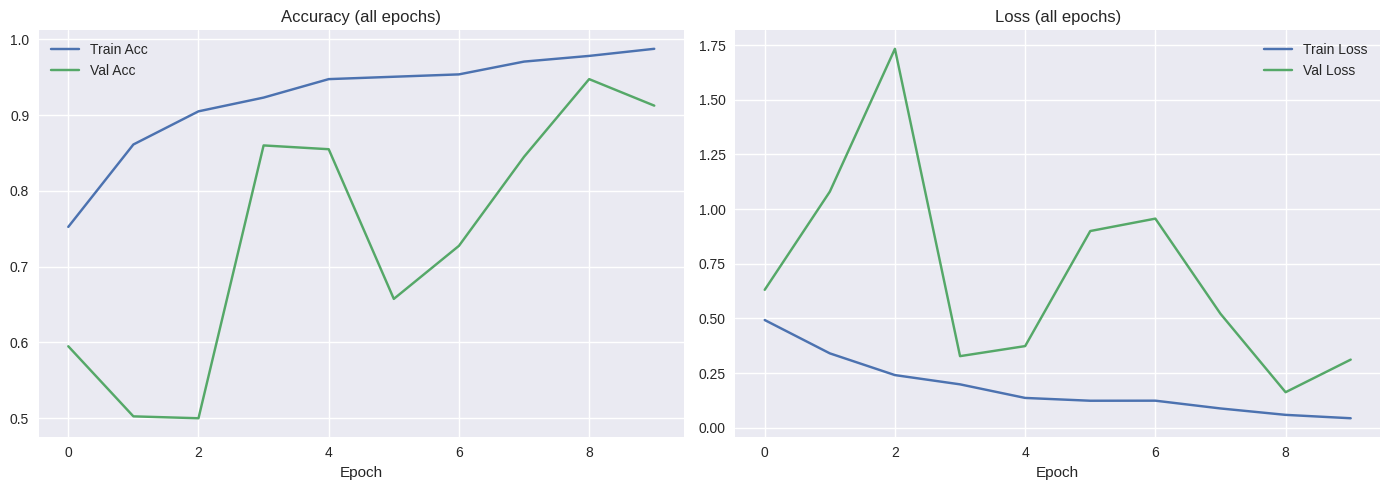

📊 Training curves saved → training_curves.png


In [18]:
print("\n🤗 HuggingFace ready →", HF_REPO_ID)
state = load_training_state()
 
start_epoch      = state["epoch"]
remaining_epochs = EPOCHS - start_epoch
print(f"\n▶️  Epoch {start_epoch + 1} → {EPOCHS}  ({remaining_epochs} epoch(s) remaining)")

print("\n📂 Scanning dataset …")
video_paths, labels = collect_video_paths(DATASET_PATH, CLASSES_LIST)
print(f"   Total videos: {len(video_paths)}")

if len(video_paths) == 0:
    raise ValueError("No videos found! Please check DATASET_PATH.")
 
paths_train, paths_val, y_train, y_val = train_test_split(
    video_paths, labels,
    test_size=0.2, random_state=42, stratify=labels,
)
print(f"   Train: {len(paths_train)}  |  Val: {len(paths_val)}")
train_gen = VideoDataGenerator(paths_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
val_gen   = VideoDataGenerator(paths_val,   y_val,   batch_size=BATCH_SIZE, shuffle=False)
print(f"Train batches: {len(train_gen)}  |  Val batches: {len(val_gen)}")
strategy = tf.distribute.MirroredStrategy()
print(f"\n🖥️  Devices in strategy: {strategy.num_replicas_in_sync}")
 
with strategy.scope():
    ckpt_found = download_from_hf(HF_MODEL_FILE, LOCAL_CKPT)
    
    # Dictionary of our custom functions so TF can load them
    custom_objs = {
        'flatten_time': flatten_time,
        'unflatten_time': unflatten_time
    }
    
    if ckpt_found and os.path.exists(LOCAL_CKPT):
        print("  🔄 Resuming from saved QAT checkpoint …")
        with tfmot.quantization.keras.quantize_scope(custom_objs):
            model = load_model(LOCAL_CKPT)
    else:
        print("  🆕 No checkpoint found – building fresh QAT model …")
        model = create_model()
 
    model.compile(
        loss="categorical_crossentropy",
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        metrics=["accuracy"],
    )
 
model.summary()

early_stop = EarlyStopping(
    monitor="val_accuracy", patience=10,
    restore_best_weights=True, verbose=1,
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5,
    patience=4, min_lr=1e-6, verbose=1,
)
hf_ckpt = HuggingFaceCheckpoint(api=api, state=state)
 
print("Callbacks ready: EarlyStopping, ReduceLROnPlateau, HuggingFaceCheckpoint")
print("\n🚀 Training Quantization-Aware Model …")

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    initial_epoch=start_epoch,
    callbacks=[early_stop, reduce_lr, hf_ckpt],
)
print("\n🏁 Training complete. Saving final QAT model …")
model.save(LOCAL_CKPT)
upload_to_hf(api, LOCAL_CKPT, HF_MODEL_FILE)
print("✅ Final Keras model uploaded.")
plot_training(history.history)

In [20]:
print("📦 Converting Model to INT8 TFLite...")

# 1. Initialize the converter from the trained Keras model
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# 2. Enable default optimizations (this applies the QAT INT8 conversions)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# 3. 🚨 THE FIX: Allow standard TensorFlow Ops for the LSTM layer
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS, 
    tf.lite.OpsSet.SELECT_TF_OPS  # Allows TF fallback for complex LSTM ops
]

# 4. 🚨 THE FIX: Disable experimental tensor list lowering
converter._experimental_lower_tensor_list_ops = False

# 5. Convert and Save
try:
    tflite_model = converter.convert()
    
    tflite_filename = "qat_video_model.tflite"
    with open(tflite_filename, "wb") as f:
        f.write(tflite_model)
        
    print(f"✅ TFLite Conversion Successful! Saved to {tflite_filename}")
except Exception as e:
    print(f"⚠️ TFLite Conversion Failed:\n{e}")

📦 Converting Model to INT8 TFLite...
INFO:tensorflow:Assets written to: /tmp/tmpv50n0xuy/assets


INFO:tensorflow:Assets written to: /tmp/tmpv50n0xuy/assets
/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


✅ TFLite Conversion Successful! Saved to qat_video_model.tflite


W0000 00:00:1776006277.077618     113 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1776006277.077678     113 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
